In [12]:
print("Proyecto 8 funcionando")



Proyecto 8 funcionando



# Proyecto 8: Energía de las olas frente a Pavones

**Curso:** Cálculo Diferencial e Integral

## Objetivo

Evaluar alternativas de convertidores de energía de las olas y baterías para suministrar electricidad a una boya marina.

Se analizan 960 registros horarios y se busca la combinación de menor costo que permita cubrir al menos el 99 % de las horas, tanto en condiciones normales como con una reducción del 20 % en la altura de las olas.

## Metodología

1. Lectura y validación de los datos originales.
2. Limpieza e interpolación de valores faltantes.
3. Integración numérica por trapecios y Simpson.
4. Cálculo del flujo energético del oleaje.
5. Simulación de convertidores y baterías.
6. Comparación de costos y disponibilidad.


In [13]:

"""Carga reproducible de los datos del Proyecto 8."""

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Identificar la raíz del proyecto, incluso si Jupyter
# se ejecuta desde la subcarpeta notebooks.
carpeta_actual = Path.cwd().resolve()

if not (carpeta_actual / "P08_C-04_HERNANDEZ.xlsx").exists():
    carpeta_actual = carpeta_actual.parent

RUTA_PROYECTO = carpeta_actual
RUTA_EXCEL = RUTA_PROYECTO / "P08_C-04_HERNANDEZ.xlsx"

if not RUTA_EXCEL.is_file():
    raise FileNotFoundError(f"No se encontró el Excel: {RUTA_EXCEL}")

if str(RUTA_PROYECTO) not in sys.path:
    sys.path.insert(0, str(RUTA_PROYECTO))

from src.procesamiento_oleaje import preparar_energia_oleaje
from src.escenarios import comparar_escenarios, seleccionar_menor_costo

# Leer todas las hojas, sin modificar el archivo original.
hojas = pd.read_excel(RUTA_EXCEL, sheet_name=None)

print("Excel cargado correctamente.")
print("\nHojas disponibles:")

for nombre, datos in hojas.items():
    print(f"- {nombre}: {datos.shape}")


Excel cargado correctamente.

Hojas disponibles:
- Registros_oleaje: (960, 4)
- Muestra_elevacion: (400, 4)
- Opciones_convertidor: (3, 5)
- Opciones_bateria: (4, 3)
- Parametros: (6, 3)
- Diccionario: (19, 4)


Horas procesadas: 960
Alturas interpoladas: 4
Flujo medio (W/m): 9548.039


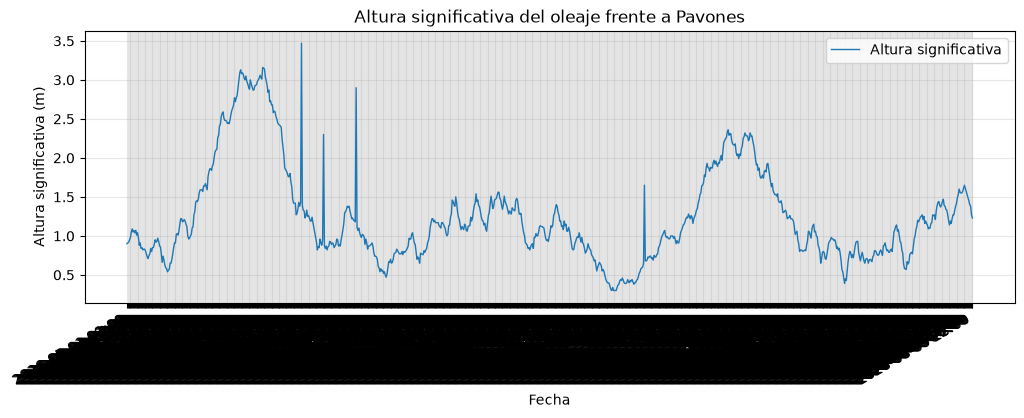

In [14]:

"""Prepara los registros y grafica la altura significativa."""

registros = preparar_energia_oleaje(
    hojas["Registros_oleaje"]
)

print("Horas procesadas:", len(registros))
print("Alturas interpoladas:", int(registros["altura_estimada"].sum()))
print(
    "Flujo medio (W/m):",
    round(registros["flujo_energia_w_m"].mean(), 3)
)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    registros["fecha_hora"],
    registros["altura_significativa_m"],
    linewidth=1,
    label="Altura significativa"
)

ax.set_title("Altura significativa del oleaje frente a Pavones")
ax.set_xlabel("Fecha")
ax.set_ylabel("Altura significativa (m)")
ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.show()



## Integración numérica y altura significativa

La varianza de elevación se aproxima mediante la integral:

$$
\sigma^2 = \frac{1}{T}\int_0^T \eta(t)^2\,dt
$$

La altura significativa del oleaje se calcula mediante:

$$
H_s = 4\sqrt{\sigma^2}
$$

Se comparan dos procedimientos:

- **Trapecio compuesto:** aproxima la integral utilizando trapecios.
- **Método híbrido:** aplica Simpson 1/3 en los primeros 198 subintervalos y trapecio en el último.

Cada muestra tiene 200 mediciones y 199 subintervalos. Por ello, no podemos aplicar Simpson 1/3 compuesto directamente a todos los intervalos.

La comparación permite comprobar la consistencia de las aproximaciones, pero una diferencia pequeña no demuestra por sí sola cuál método es más exacto.


In [15]:

"""Compara los métodos de integración en las muestras reales."""

from src.calculos_oleaje import calcular_por_registro

muestras = hojas["Muestra_elevacion"]

resultado_trapecio = calcular_por_registro(
    muestras, metodo="trapecio"
)

resultado_hibrido = calcular_por_registro(
    muestras, metodo="hibrido"
)

comparacion_integrales = pd.DataFrame({
    "Registro": resultado_trapecio["registro"],
    "Hs trapecio (m)": resultado_trapecio["altura_significativa_m"],
    "Hs híbrido (m)": resultado_hibrido["altura_significativa_m"],
})

comparacion_integrales["Diferencia (m)"] = (
    comparacion_integrales["Hs híbrido (m)"]
    - comparacion_integrales["Hs trapecio (m)"]
)

display(comparacion_integrales.round(6))


,Registro,Hs trapecio (m),Hs híbrido (m),Diferencia (m)
0,1,1.467543,1.467057,-0.000486
1,2,1.128478,1.128013,-0.000464



## Modelo de energía del oleaje

El flujo energético por metro de frente de ola se calcula mediante:

$$
J = \frac{\rho g^2}{64\pi} H_s^2 T_e
$$

Donde:

- $\rho = 1025\ \mathrm{kg/m^3}$: densidad del agua de mar.
- $g = 9.81\ \mathrm{m/s^2}$: aceleración gravitacional.
- $H_s$: altura significativa del oleaje.
- $T_e = 0.9T_p$: período energético.

La potencia eléctrica generada por un convertidor es:

$$
P_g = \min(P_{\mathrm{nom}}, \eta b J)
$$

El sistema debe cubrir un consumo continuo de 300 W durante al menos el 99 % de las 960 horas.

Para el escenario adverso se reduce la altura de las olas un 20 %, manteniendo constante el período. Como el flujo depende de $H_s^2$, queda multiplicado por $0.64$.


In [16]:

"""Evalúa convertidores y baterías en ambos escenarios."""

convertidores = hojas["Opciones_convertidor"]
baterias = hojas["Opciones_bateria"]

comparacion_sistemas = comparar_escenarios(
    registros,
    convertidores,
    baterias,
    consumo_w=300.0,
    reduccion=0.20,
)

columnas_resumen = [
    "convertidor",
    "bateria",
    "costo_total_colones",
    "disponibilidad_base_pct",
    "disponibilidad_reducido_pct",
    "cumple_ambos",
]

display(comparacion_sistemas[columnas_resumen].round(2))

mejor = seleccionar_menor_costo(comparacion_sistemas)

if mejor is None:
    print("Ninguna combinación cumple ambos escenarios.")
else:
    print("\nSISTEMA RECOMENDADO")
    print("Convertidor:", mejor["convertidor"])
    print("Batería:", mejor["bateria"])
    print("Costo total: ₡{:,.0f}".format(mejor["costo_total_colones"]))
    print(
        "Disponibilidad normal:",
        f"{mejor['disponibilidad_base_pct']:.2f}%"
    )
    print(
        "Disponibilidad reducida:",
        f"{mejor['disponibilidad_reducido_pct']:.2f}%"
    )


,convertidor,bateria,costo_total_colones,disponibilidad_base_pct,disponibilidad_reducido_pct,cumple_ambos
0,WEC-50,B2,4170000,37.50,26.88,False
1,WEC-50,B5,5150000,42.81,31.25,False
2,WEC-100,B2,6930000,73.65,46.98,False
3,WEC-50,B10,7290000,51.88,38.54,False
4,WEC-100,B5,7910000,81.88,53.65,False
5,WEC-150,B2,9620000,94.79,80.10,False
6,WEC-100,B10,10050000,91.88,61.98,False
7,WEC-50,B20,10540000,63.65,49.17,False
8,WEC-150,B5,10600000,96.88,86.98,False
9,WEC-150,B10,12740000,99.48,96.98,False



SISTEMA RECOMENDADO
Convertidor: WEC-150
Batería: B20
Costo total: ₡15,990,000
Disponibilidad normal: 100.00%
Disponibilidad reducida: 100.00%


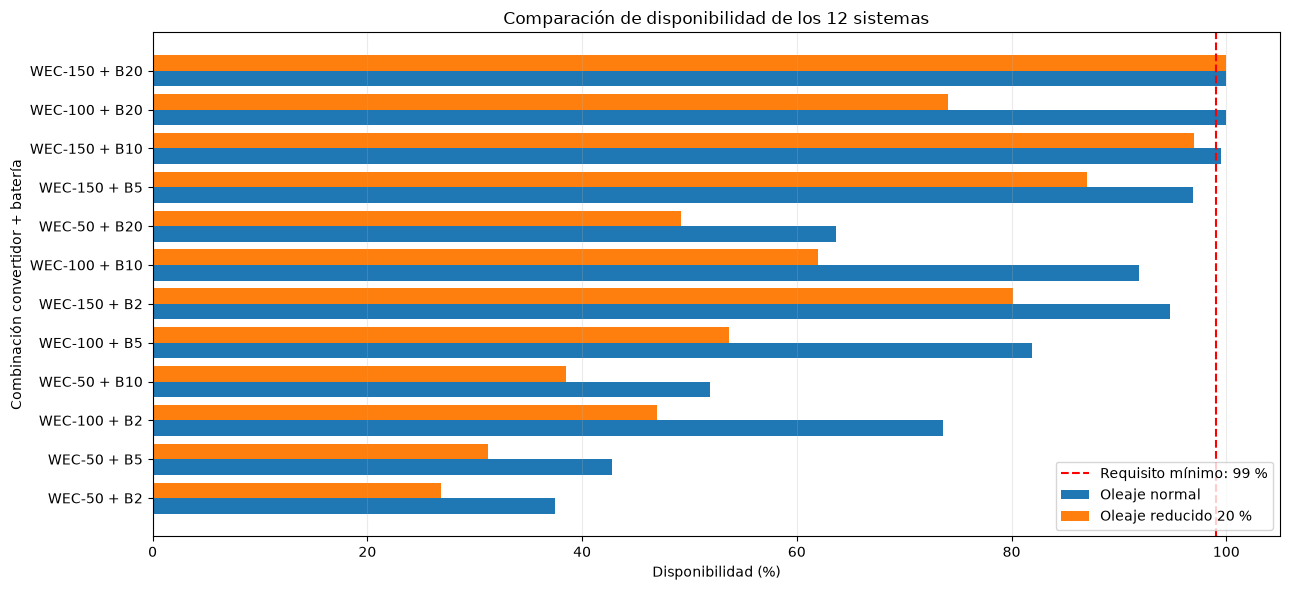

In [17]:

"""Compara la disponibilidad de las 12 combinaciones."""

import matplotlib.pyplot as plt

# Preparar etiquetas y ordenar los sistemas por costo.
datos_grafico = comparacion_sistemas.sort_values(
    "costo_total_colones"
).copy()

etiquetas = (
    datos_grafico["convertidor"]
    + " + "
    + datos_grafico["bateria"]
)

posiciones = range(len(datos_grafico))

fig, ax = plt.subplots(figsize=(13, 6))

ax.barh(
    [p - 0.2 for p in posiciones],
    datos_grafico["disponibilidad_base_pct"],
    height=0.4,
    label="Oleaje normal",
)

ax.barh(
    [p + 0.2 for p in posiciones],
    datos_grafico["disponibilidad_reducido_pct"],
    height=0.4,
    label="Oleaje reducido 20 %",
)

# Línea de disponibilidad mínima requerida.
ax.axvline(
    99,
    color="red",
    linestyle="--",
    label="Requisito mínimo: 99 %",
)

ax.set_yticks(list(posiciones))
ax.set_yticklabels(etiquetas)

ax.set_xlabel("Disponibilidad (%)")
ax.set_ylabel("Combinación convertidor + batería")
ax.set_title("Comparación de disponibilidad de los 12 sistemas")
ax.set_xlim(0, 105)

ax.legend()
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()



## Conclusiones preliminares

Se evaluaron 12 combinaciones de convertidores y baterías durante 960 horas.

La combinación **WEC-150 + B20** fue la alternativa de menor costo que cumplió el requisito mínimo del 99 % en ambos escenarios:

- **Costo total:** ₡15,990,000.
- **Disponibilidad con oleaje normal:** 100 %.
- **Disponibilidad con oleaje reducido 20 %:** 100 %.
- **Horas sin cobertura:** 0 en ambos escenarios.

La simulación supone una batería inicialmente cargada al 100 %, eficiencia ideal de carga y descarga y consumo constante de 300 W.

Los resultados no incluyen pérdidas adicionales, degradación de baterías ni condiciones meteorológicas fuera del período observado.

Por tanto, la solución es válida bajo los supuestos del modelo y debe interpretarse como una recomendación académica, no como una garantía de funcionamiento real.
